In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
print("Pustaka Support Vector Machine (SVM) dan GridSearchCV berhasil dimuat.")

Pustaka Support Vector Machine (SVM) dan GridSearchCV berhasil dimuat.


In [2]:
# Memuat data ulasan dan aspek
path_reviews = '../outputs/reviews_preprocessed.csv'
if not os.path.exists(path_reviews):
    path_reviews = '../dataset/reviews.csv'
path_aspects = '../dataset/aspect_sentiments.csv'

df_reviews = pd.read_csv(path_reviews)
df_aspects = pd.read_csv(path_aspects)

if 'cleaned_text' not in df_reviews.columns:
    df_reviews['cleaned_text'] = df_reviews['text'].str.lower().str.replace(r'[^a-zA-Z\s]', ' ', regex=True).str.strip()

df_data = pd.merge(df_aspects[['review_id', 'sentiment']], df_reviews[['id', 'cleaned_text']], left_on='review_id', right_on='id')
df_data = df_data[df_data['cleaned_text'].str.len() > 3].drop_duplicates(subset=['id', 'sentiment']).reset_index(drop=True)

X_text = df_data['cleaned_text']
y      = df_data['sentiment']

# Stratified Splitting 80% Train, 20% Test
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_text, y, test_size=0.20, random_state=42, stratify=y
)

# Ekstraksi fitur TF-IDF
vec_tfidf = TfidfVectorizer(max_features=800, min_df=3, ngram_range=(1, 2), sublinear_tf=True)
X_train_vec = vec_tfidf.fit_transform(X_train_raw)
X_test_vec  = vec_tfidf.transform(X_test_raw)

print(f"Dataset Sentimen siap diproses SVM: {X_train_vec.shape[0]} train, {X_test_vec.shape[0]} test")

Dataset Sentimen siap diproses SVM: 5296 train, 1324 test


In [3]:
# Melatih SVM Linear dan RBF baseline (C = 1.0)
svm_linear = SVC(kernel='linear', C=1.0, random_state=42)
svm_rbf    = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)

svm_linear.fit(X_train_vec, y_train)
svm_rbf.fit(X_train_vec, y_train)

pred_linear = svm_linear.predict(X_test_vec)
pred_rbf    = svm_rbf.predict(X_test_vec)

acc_lin = accuracy_score(y_test, pred_linear)
acc_rbf = accuracy_score(y_test, pred_rbf)

print("=== PERBANDINGAN PERFORMA KERNEL SVM (C=1.0) ===")
print(f"- Akurasi SVM Linear : {acc_lin*100:.2f}% | Support Vectors: {svm_linear.n_support_.sum()}")
print(f"- Akurasi SVM RBF    : {acc_rbf*100:.2f}% | Support Vectors: {svm_rbf.n_support_.sum()}")

=== PERBANDINGAN PERFORMA KERNEL SVM (C=1.0) ===
- Akurasi SVM Linear : 75.00% | Support Vectors: 3059
- Akurasi SVM RBF    : 70.85% | Support Vectors: 3750


In [4]:
# Parameter grid untuk GridSearchCV
param_grid = {
    'C': [0.5, 1.0, 5.0, 10.0],
    'kernel': ['linear', 'rbf']
}

grid_search = GridSearchCV(
    estimator=SVC(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_vec, y_train)

print(f"Parameter Terbaik Hasil GridSearch: {grid_search.best_params_}")
print(f"Skor Akurasi Rata-rata CV Terbaik  : {grid_search.best_score_*100:.2f}%")

best_svm = grid_search.best_estimator_
y_pred_best = best_svm.predict(X_test_vec)

print("\nClassification Report Model SVM Terbaik pada Data Uji:")
print(classification_report(y_test, y_pred_best, digits=4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Parameter Terbaik Hasil GridSearch: {'C': 0.5, 'kernel': 'linear'}
Skor Akurasi Rata-rata CV Terbaik  : 74.92%

Classification Report Model SVM Terbaik pada Data Uji:
              precision    recall  f1-score   support

    negative     1.0000    0.0938    0.1714        64
     neutral     0.6831    0.6525    0.6674       446
    positive     0.8016    0.8784    0.8382       814

    accuracy                         0.7644      1324
   macro avg     0.8282    0.5415    0.5590      1324
weighted avg     0.7713    0.7644    0.7485      1324



<string>:35: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



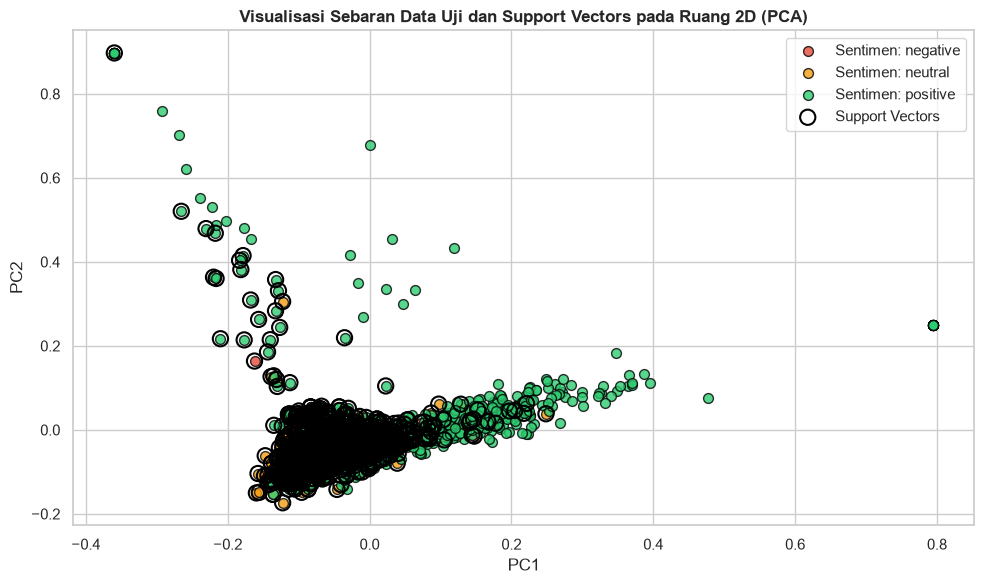

In [5]:
# Proyeksi data uji ke 2 Komponen Utama (PC1 dan PC2) untuk visualisasi batas keputusan
pca = PCA(n_components=2, random_state=42)
X_test_pca = pca.fit_transform(X_test_vec.toarray())

# Melatih SVM Linear visual pada ruang 2D
svm_vis = SVC(kernel='linear', C=1.0, random_state=42)
svm_vis.fit(X_test_pca, y_test)

# Membuat meshgrid batas keputusan
x_min, x_max = X_test_pca[:, 0].min() - 0.2, X_test_pca[:, 0].max() + 0.2
y_min, y_max = X_test_pca[:, 1].min() - 0.2, X_test_pca[:, 1].max() + 0.2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

# Visualisasi scatter plot
plt.figure(figsize=(10, 6))
class_labels = sorted(y.unique())
label_map = {lbl: i for i, lbl in enumerate(class_labels)}
y_num = np.array([label_map[l] for l in y_test])

palette = ['#e74c3c', '#f39c12', '#2ecc71']
for i, lbl in enumerate(class_labels):
    mask = y_test == lbl
    plt.scatter(X_test_pca[mask, 0], X_test_pca[mask, 1], label=f'Sentimen: {lbl}',
                alpha=0.8, edgecolors='black', s=50, color=palette[i])

# Tandai support vectors
sv = svm_vis.support_vectors_
plt.scatter(sv[:, 0], sv[:, 1], s=120, facecolors='none', edgecolors='black', linewidths=1.5, label='Support Vectors')

plt.title('Visualisasi Sebaran Data Uji dan Support Vectors pada Ruang 2D (PCA)', fontsize=12, fontweight='bold')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.tight_layout()
plt.show()

<string>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



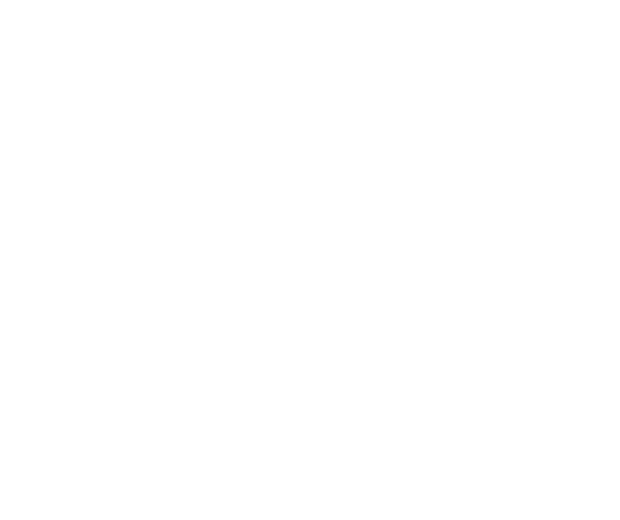

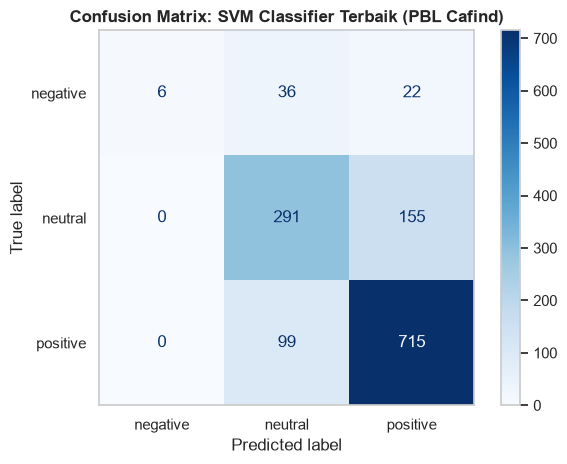

In [6]:
cm_svm = confusion_matrix(y_test, y_pred_best, labels=class_labels)

plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=class_labels)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix: SVM Classifier Terbaik (PBL Cafind)', fontsize=12, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

In [7]:
import joblib

os.makedirs('../outputs', exist_ok=True)
path_saved_svm = '../outputs/svm_sentiment_model_js11.joblib'
joblib.dump({'model': best_svm, 'vectorizer': vec_tfidf, 'params': grid_search.best_params_}, path_saved_svm)
print(f"Model SVM Terbaik berhasil disimpan ke: {path_saved_svm}")

Model SVM Terbaik berhasil disimpan ke: ../outputs/svm_sentiment_model_js11.joblib
